# Task 2

---

## Predictive modeling of customer bookings

This Jupyter notebook includes some code to get you started with this predictive modeling task. We will use various packages for data manipulation, feature engineering and machine learning.

### Exploratory data analysis

First, we must explore the data in order to better understand what we have and the statistical properties of the dataset.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("customer_booking.csv", encoding="ISO-8859-1")
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


The `.head()` method allows us to view the first 5 rows in the dataset, this is useful for visual inspection of our columns

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

The `.info()` method gives us a data description, telling us the names of the columns, their data types and how many null values we have. Fortunately, we have no null values. It looks like some of these columns should be converted into different data types, e.g. flight_day.

To provide more context, below is a more detailed data description, explaining exactly what each column means:

- `num_passengers` = number of passengers travelling
- `sales_channel` = sales channel booking was made on
- `trip_type` = trip Type (Round Trip, One Way, Circle Trip)
- `purchase_lead` = number of days between travel date and booking date
- `length_of_stay` = number of days spent at destination
- `flight_hour` = hour of flight departure
- `flight_day` = day of week of flight departure
- `route` = origin -> destination flight route
- `booking_origin` = country from where booking was made
- `wants_extra_baggage` = if the customer wanted extra baggage in the booking
- `wants_preferred_seat` = if the customer wanted a preferred seat in the booking
- `wants_in_flight_meals` = if the customer wanted in-flight meals in the booking
- `flight_duration` = total duration of flight (in hours)
- `booking_complete` = flag indicating if the customer completed the booking

Before we compute any statistics on the data, lets do any necessary data conversion

In [4]:
df["flight_day"].unique()

array(['Sat', 'Wed', 'Thu', 'Mon', 'Sun', 'Tue', 'Fri'], dtype=object)

In [5]:
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

df["flight_day"] = df["flight_day"].map(mapping)

In [6]:
df["flight_day"].unique()

array([6, 3, 4, 1, 7, 2, 5], dtype=int64)

In [7]:
df.describe()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
count,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,1.591240,84.940480,23.04456,9.06634,3.814420,0.668780,0.296960,0.427140,7.277561,0.149560
std,1.020165,90.451378,33.88767,5.41266,1.992792,0.470657,0.456923,0.494668,1.496863,0.356643
min,1.000000,0.000000,0.00000,0.00000,1.000000,0.000000,0.000000,0.000000,4.670000,0.000000
25%,1.000000,21.000000,5.00000,5.00000,2.000000,0.000000,0.000000,0.000000,5.620000,0.000000
50%,1.000000,51.000000,17.00000,9.00000,4.000000,1.000000,0.000000,0.000000,7.570000,0.000000
75%,2.000000,115.000000,28.00000,13.00000,5.000000,1.000000,1.000000,1.000000,8.830000,0.000000
max,9.000000,867.000000,778.00000,23.00000,7.000000,1.000000,1.000000,1.000000,9.500000,1.000000


The `.describe()` method gives us a summary of descriptive statistics over the entire dataset (only works for numeric columns). This gives us a quick overview of a few things such as the mean, min, max and overall distribution of each column.

From this point, you should continue exploring the dataset with some visualisations and other metrics that you think may be useful. Then, you should prepare your dataset for predictive modelling. Finally, you should train your machine learning model, evaluate it with performance metrics and output visualisations for the contributing variables. All of this analysis should be summarised in your single slide.

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import warnings

warnings.filterwarnings('ignore')

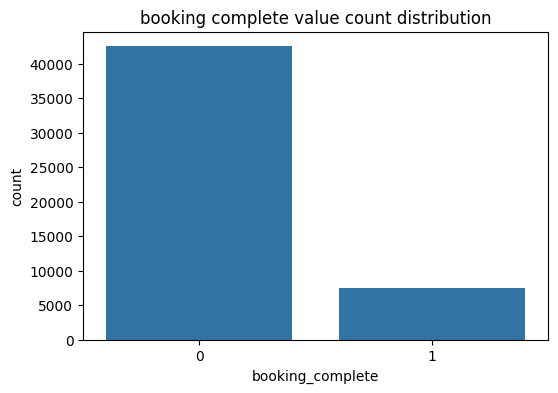

booking_complete
0    85.044
1    14.956
Name: proportion, dtype: float64

In [9]:
#Target Variable Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='booking_complete',data=df)
plt.title("booking complete value count distribution")
plt.show()
# Percentage
df['booking_complete'].value_counts(normalize=True) * 100

Analyzing categorical features:


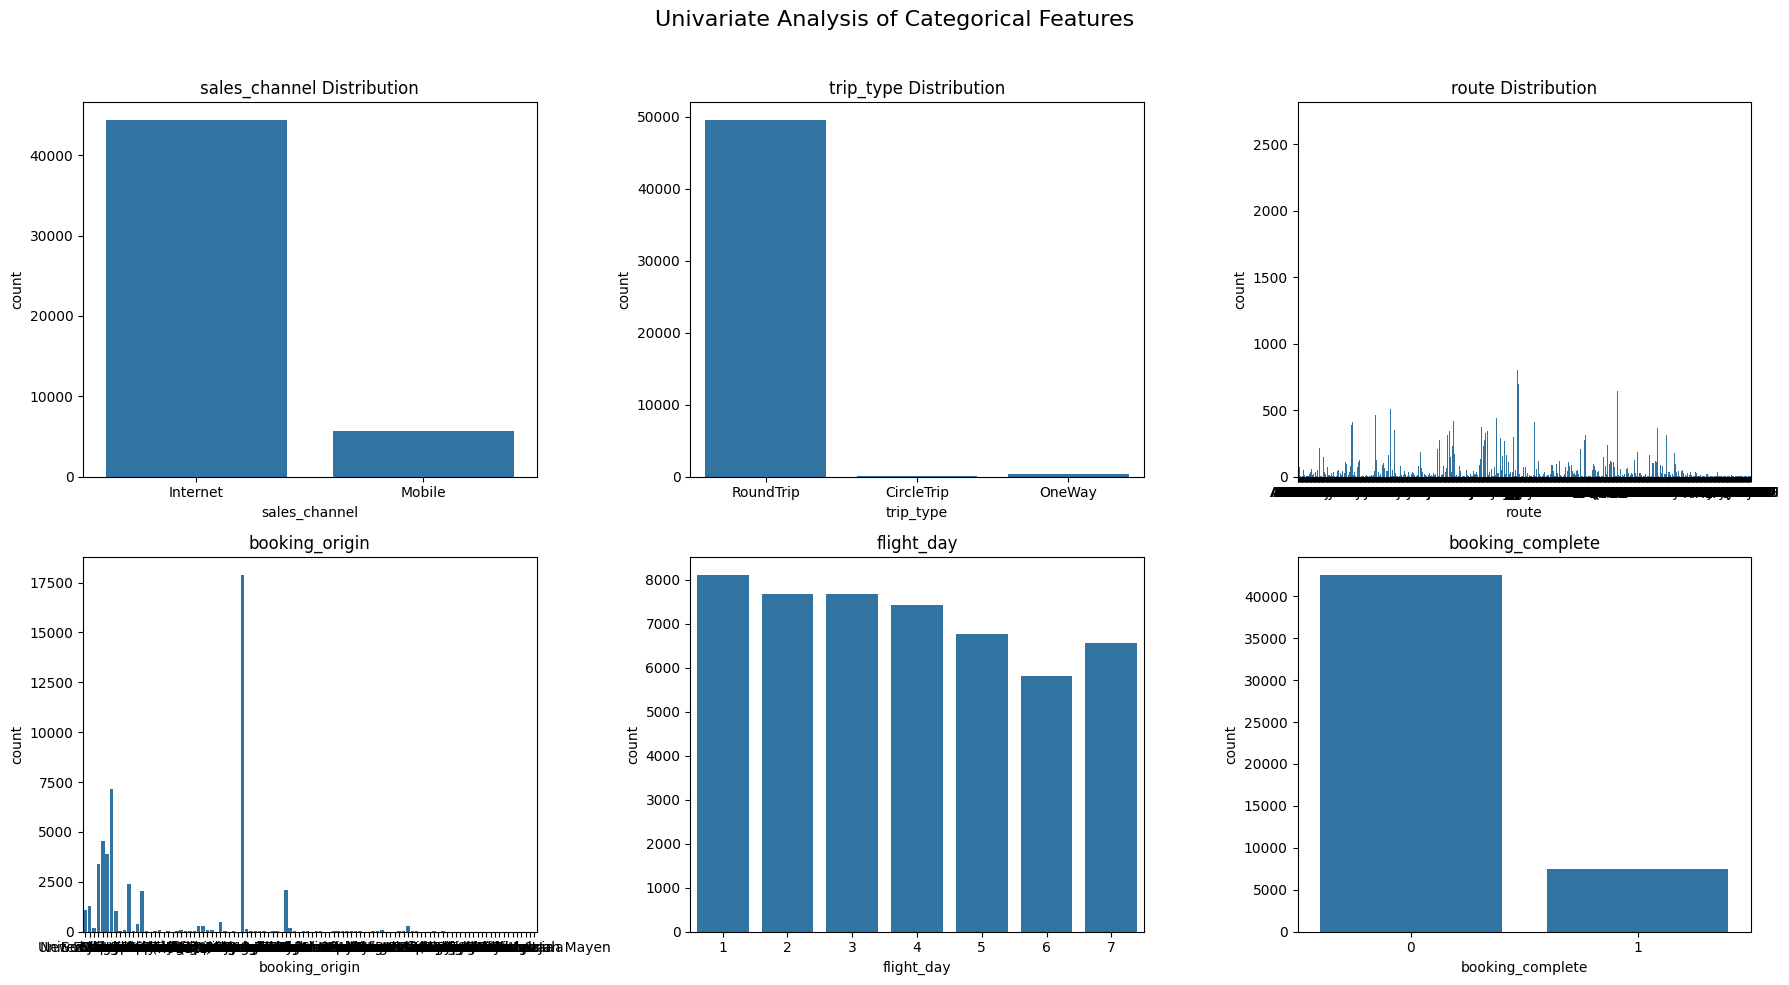

In [10]:
print("Analyzing categorical features:")

# Set up the figure for plotting
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Univariate Analysis of Categorical Features', fontsize=16)

# Plotting each categorical feature
sns.countplot(ax=axes[0, 0], x='sales_channel', data=df).set_title('sales_channel Distribution')
sns.countplot(ax=axes[0, 1], x='trip_type', data=df).set_title('trip_type Distribution')
sns.countplot(ax=axes[0, 2], x='route', data=df).set_title('route Distribution')
sns.countplot(ax=axes[1, 0], x='booking_origin', data=df).set_title('booking_origin')
sns.countplot(ax=axes[1, 1], x='flight_day', data=df).set_title('flight_day')
sns.countplot(ax=axes[1, 2], x='booking_complete', data=df).set_title('booking_complete')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

- Internet bookings are extremely high.
Mobile bookings are very low.

- RoundTrip dominates dataset.
OneWay and CircleTrip are very small.

- Many routes with small counts.
Few routes have very high frequency.

- One country dominates heavily.
Others are very small.

- All days fairly evenly distributed.
Slight variation but not extreme.

- 0 (not completed) is much higher than 1.
Strong class imbalance.

In [11]:
num_cols=df.select_dtypes(include=["int64","float64"]).columns.to_list()
num_cols.remove("booking_complete")

cat_cols=df.select_dtypes(include=["object"]).columns.to_list()

print("Numerical:", num_cols)
print("Categorical:", cat_cols)


Numerical: ['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour', 'flight_day', 'wants_extra_baggage', 'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration']
Categorical: ['sales_channel', 'trip_type', 'route', 'booking_origin']



Analyzing numerical features:


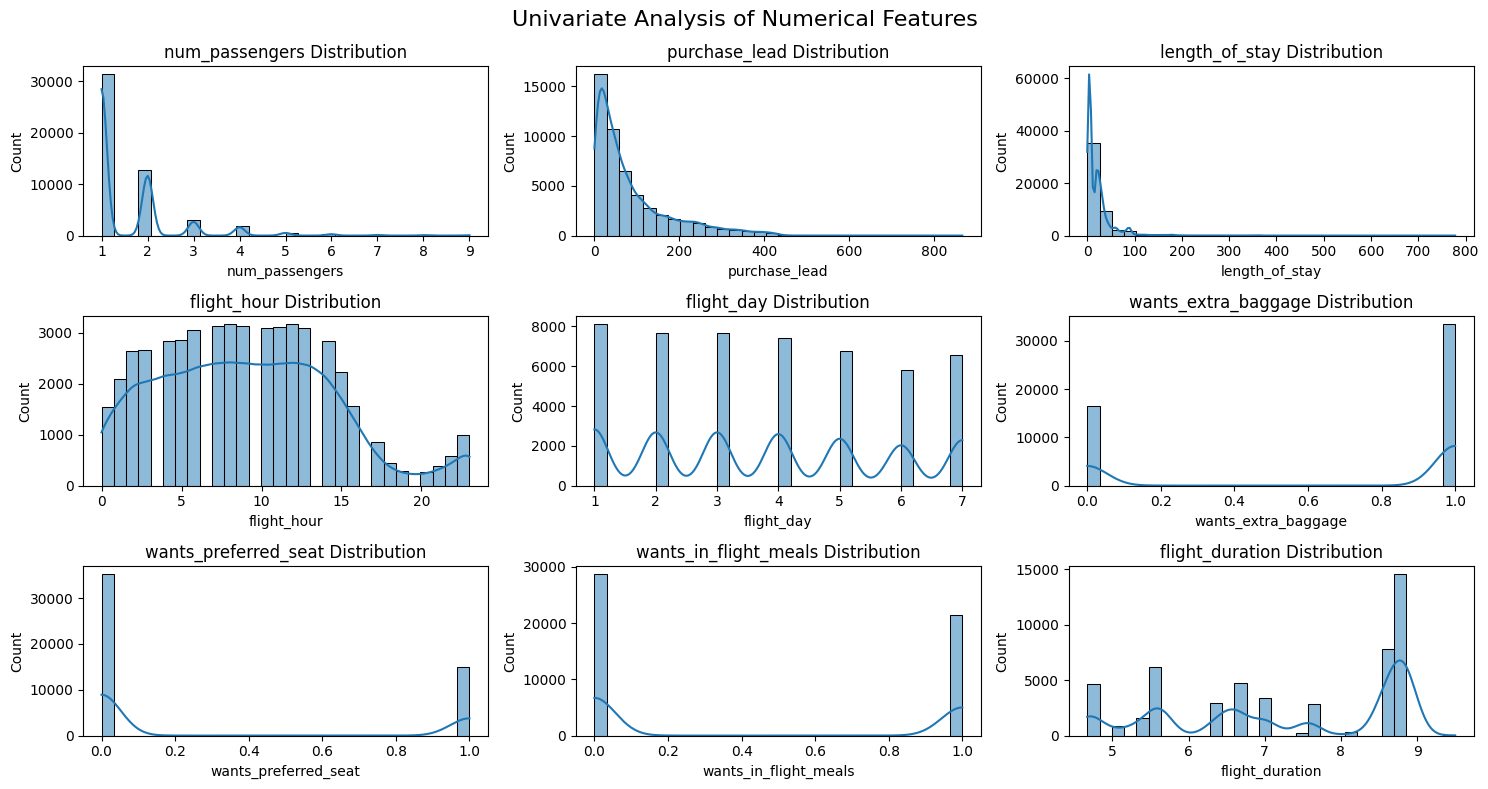

In [12]:
print("\nAnalyzing numerical features:")

fig, axes = plt.subplots(3, 3, figsize=(15, 8))
axes = axes.flatten()

fig.suptitle('Univariate Analysis of Numerical Features', fontsize=16)

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True, bins=30)
    axes[i].set_title(f'{col} Distribution')

plt.tight_layout()
plt.show()


- Solo/couple travelers dominate.
- Customers book closer to travel date.
- Extra baggage is very popular.
- Most routes are mid/long haul.
- Stay duration and lead time are highly skewed.

Bivariate Analysis: cat Feature vs. target


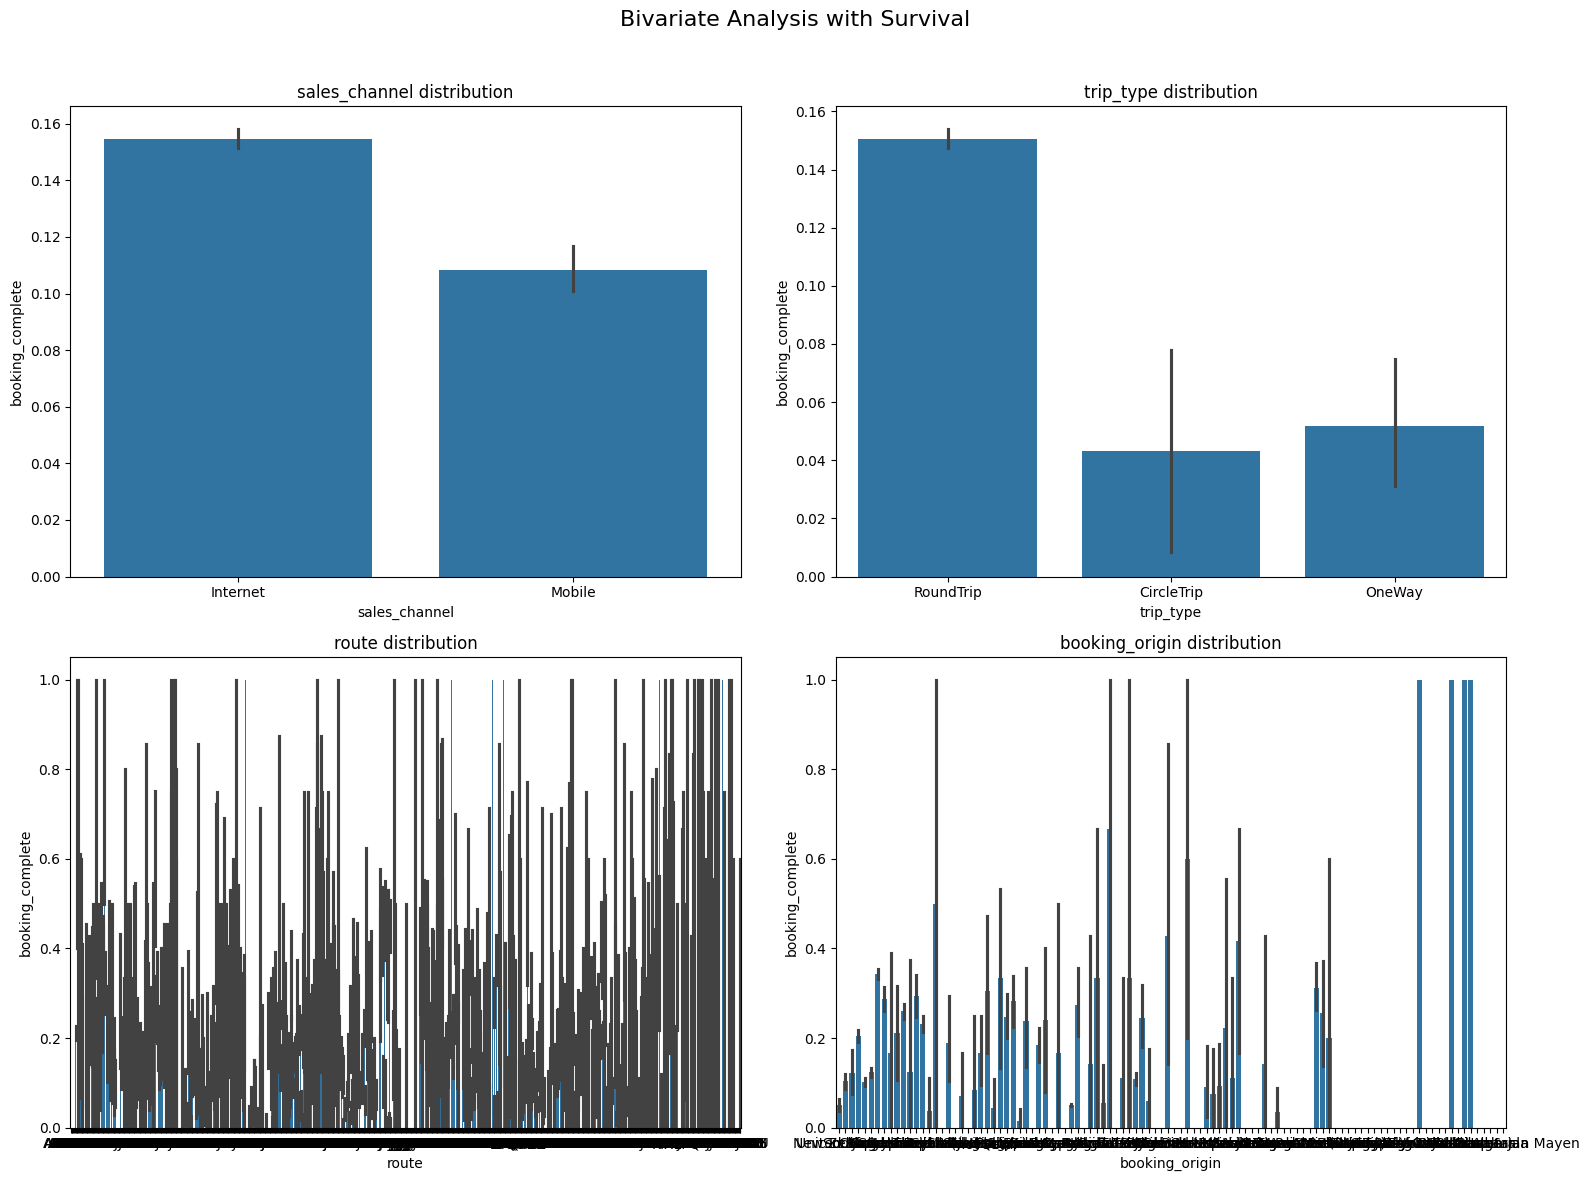

In [13]:
print("Bivariate Analysis: cat Feature vs. target")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()
fig.suptitle('Bivariate Analysis with Survival', fontsize=16)

for i, col in enumerate(cat_cols):
    # cat col vs. Survived
    sns.barplot(data=df, x=col, y='booking_complete', ax=axes[i]).set_title(f'{col} distribution')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

- Internet has higher booking completion rate (~15–16%)
Mobile is lower (~10–11%)
Customers booking via Internet are more likely to complete booking than mobile users.
- RoundTrip → highest completion (~15%)
OneWay → lower (~5%)
CircleTrip → lowest (~4%)
RoundTrip customers are much more likely to complete booking.
- Route has high cardinality (too many categories).
Plot is cluttered → not useful visually.
- Booking origin strongly affects completion probability.

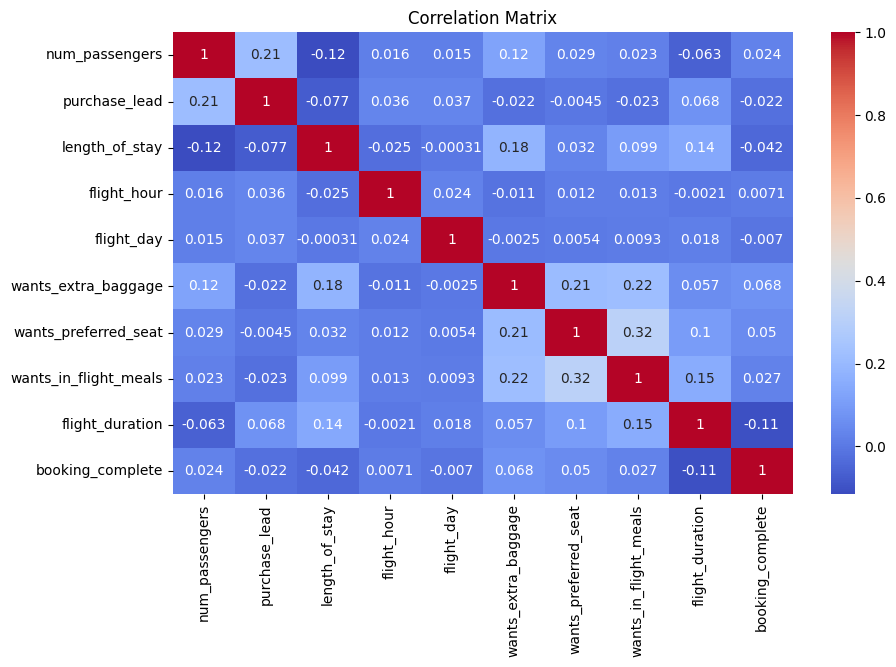

In [14]:
plt.figure(figsize=(10,6))
corr = df[num_cols + ['booking_complete']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()


- flight_duration
-0.11
Strongest signal
Definitely keep
- wants_extra_baggage	+0.068	Moderate positive	Keep
- wants_preferred_seat	+0.050	Moderate positive	Keep
- length_of_stay
-0.042
Weak negative
Possible

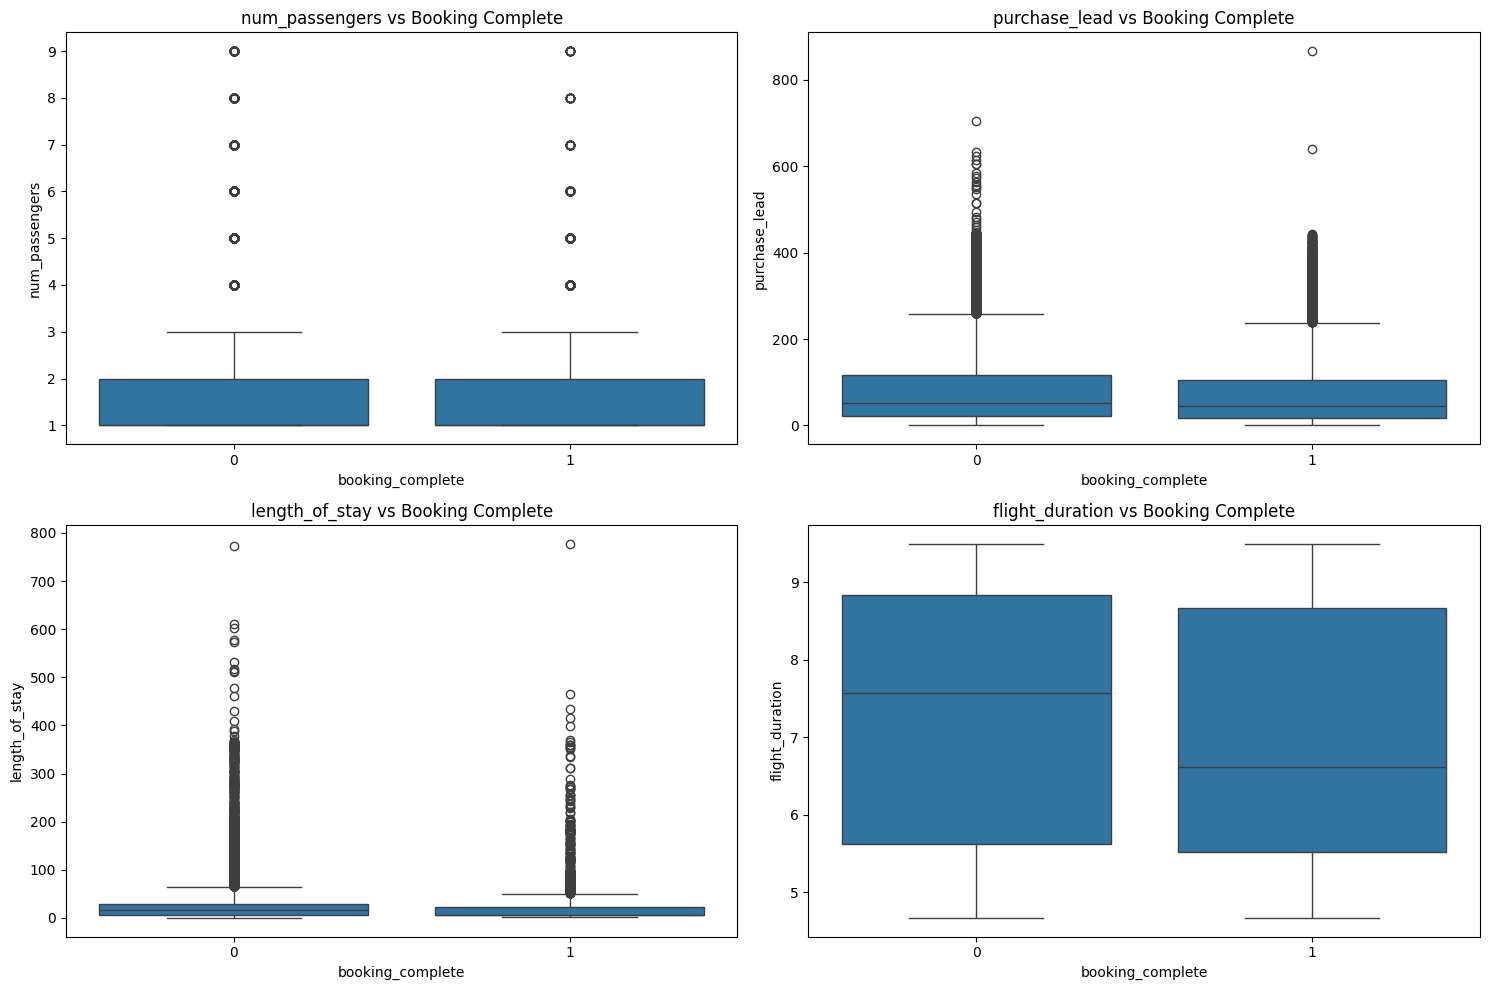

In [15]:
continuous_cols = [
    'num_passengers',
    'purchase_lead',
    'length_of_stay',
    'flight_duration'
]

plt.figure(figsize=(15, 10))

for i, col in enumerate(continuous_cols):
    plt.subplot(2, 2, i+1)
    sns.boxplot(data=df,
                x='booking_complete',
                y=col)
    plt.title(f'{col} vs Booking Complete')

plt.tight_layout()
plt.show()


- Median is similar for both classes (mostly 1–2 passengers).
No strong separation between 0 and 1.
Outliers exist in both groups.
Insight:
Number of passengers does not strongly influence booking completion.

- Both classes are highly right-skewed.
Slightly lower median lead time for completed bookings.
Heavy outliers in both classes.
Insight:
Customers who book closer to departure date may be slightly more likely to complete.
Effect is present but not very strong.
Moderate predictor (after transformation).

- Very skewed.
Medians are similar.
Extreme outliers in both classes.
Insight:
Length of stay shows very weak separation between completed and non-completed bookings.

- Class 0 has slightly higher median duration.
Completed bookings (1) slightly lower median.
Some visible separation.
Insight:
Flight duration has some predictive signal.
Medium-duration flights may convert differently than long ones.

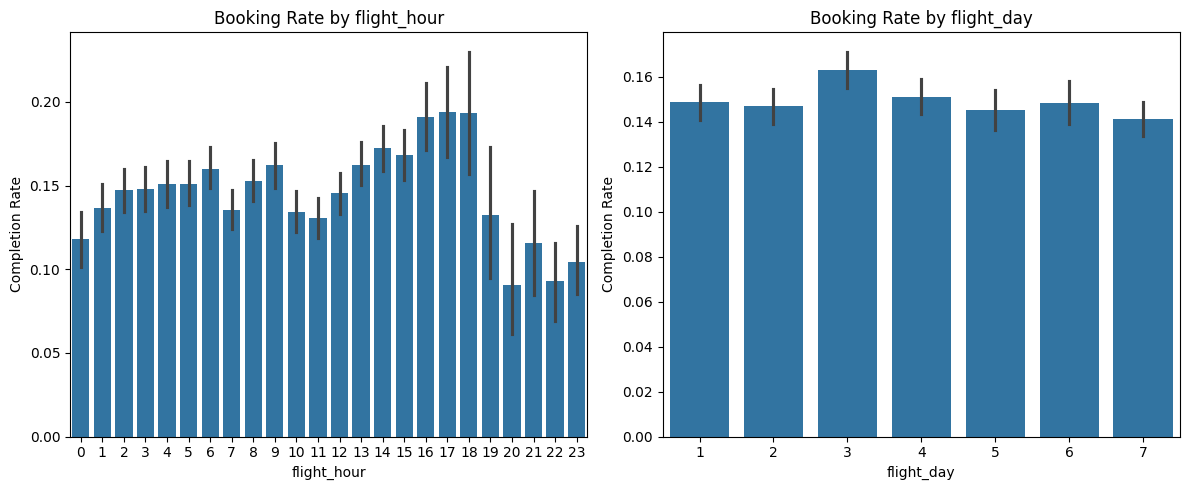

In [16]:
time_cols = ['flight_hour', 'flight_day']

plt.figure(figsize=(12, 5))

for i, col in enumerate(time_cols):
    plt.subplot(1, 2, i+1)
    sns.barplot(data=df,
                x=col,
                y='booking_complete',
                estimator='mean')
    plt.title(f'Booking Rate by {col}')
    plt.ylabel('Completion Rate')

plt.tight_layout()
plt.show()


- Completion rate increases from morning to evening.
Peak around 16–18 hours (~19–20%).
Drops significantly after 19–20 hours.
Insight:
Afternoon/evening flights convert better.
Late-night flights convert worse.

- Fairly stable across days.
Slight peak around Day 3.
Small variation overall.
Insight:
Flight day does not strongly impact booking completion.

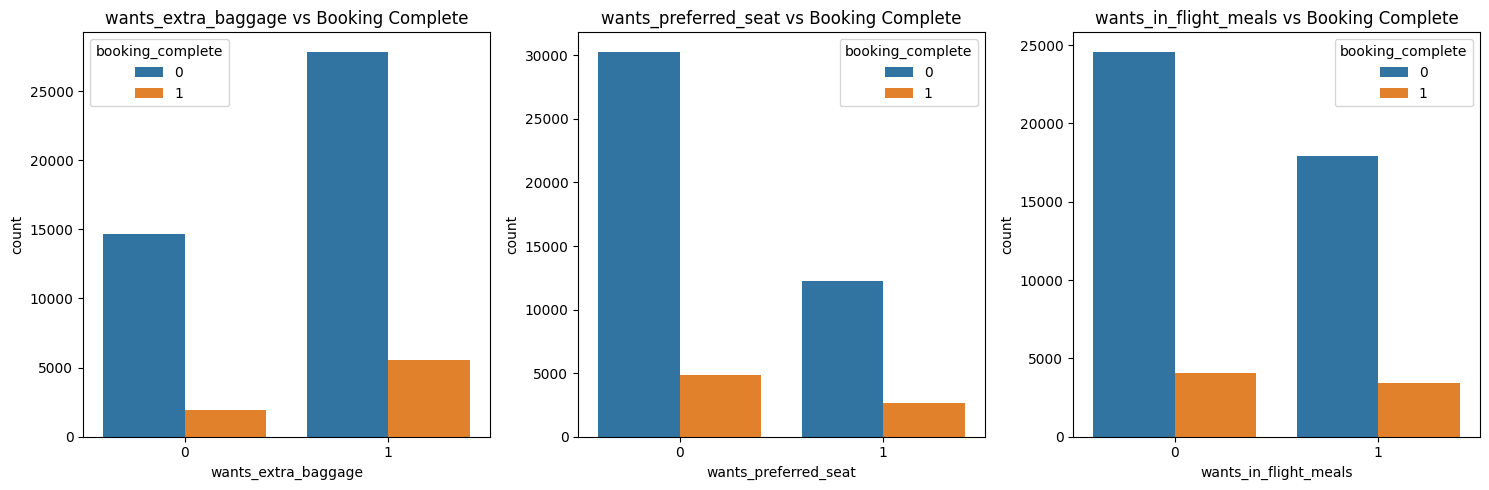

In [17]:
binary_cols = [
    'wants_extra_baggage',
    'wants_preferred_seat',
    'wants_in_flight_meals'
]

plt.figure(figsize=(15, 5))

for i, col in enumerate(binary_cols):
    plt.subplot(1, 3, i+1)
    sns.countplot(data=df,
                  x=col,
                  hue='booking_complete')
    plt.title(f'{col} vs Booking Complete')

plt.tight_layout()
plt.show()


- Customers selecting extra baggage are much more likely to complete booking.
- Seat selection increases probability of booking completion.
But effect is weaker than baggage.
- Customers selecting meals show higher completion.
Clear separation visible.
Insight:
Meal selection is a strong indicator of serious buyers.

In [18]:
for col in binary_cols:
    print(df.groupby(col)['booking_complete'].mean())


wants_extra_baggage
0    0.115029
1    0.166662
Name: booking_complete, dtype: float64
wants_preferred_seat
0    0.137944
1    0.177061
Name: booking_complete, dtype: float64
wants_in_flight_meals
0    0.141396
1    0.160509
Name: booking_complete, dtype: float64


- Customers NOT selecting baggage → 11.5% complete
Customers selecting baggage → 16.6% complete
Difference:
16.6% − 11.5% = +5.1% absolute increase
That is a large jump.
Insight:
Selecting extra baggage significantly increases likelihood of booking completion.

- Difference:
+3.92% increase
Insight:
Customers choosing preferred seats are more likely to complete.

- Meal selection also increases completion probability,
but effect is smaller compared to baggage and seat.

In [19]:
for col in cat_cols:
    print(f"\nCompletion Rate by {col}")
    display(df.groupby(col)['booking_complete'].mean().sort_values(ascending=False))



Completion Rate by sales_channel


sales_channel
Internet    0.154770
Mobile      0.108402
Name: booking_complete, dtype: float64


Completion Rate by trip_type


trip_type
RoundTrip     0.150575
OneWay        0.051680
CircleTrip    0.043103
Name: booking_complete, dtype: float64


Completion Rate by route


route
CKGSGN    1.0
JOGKTM    1.0
KOSSYD    1.0
CXRMEL    1.0
KTMURT    1.0
         ... 
HNDTRZ    0.0
AKLHGH    0.0
HNDOOL    0.0
HNDMLE    0.0
URTXIY    0.0
Name: booking_complete, Length: 799, dtype: float64


Completion Rate by booking_origin


booking_origin
Seychelles          1.000000
Iraq                1.000000
Pakistan            1.000000
Vanuatu             1.000000
Kazakhstan          0.666667
                      ...   
Colombia            0.000000
Panama              0.000000
Papua New Guinea    0.000000
Peru                0.000000
Maldives            0.000000
Name: booking_complete, Length: 104, dtype: float64

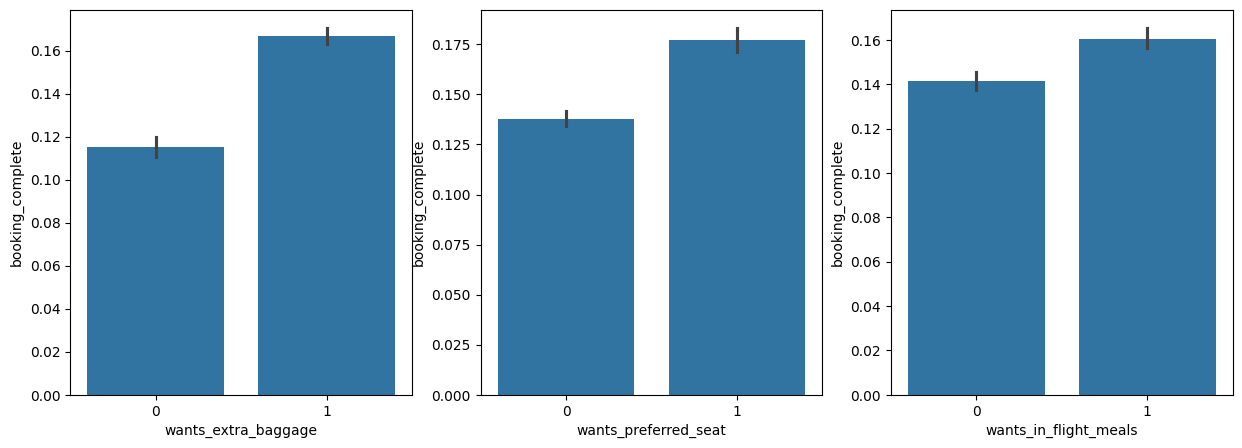

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

<Figure size 600x400 with 0 Axes>

In [20]:
service_cols = [
    'wants_extra_baggage',
    'wants_preferred_seat',
    'wants_in_flight_meals'
]
fig,axes=plt.subplots(1,3,figsize=(15,5))
axes=axes.flatten()
for i,col in enumerate(service_cols):
    plt.figure(figsize=(6,4))
    sns.barplot(data=df,x=col, y='booking_complete',ax=axes[i])
plt.tight_layout()
plt.show()


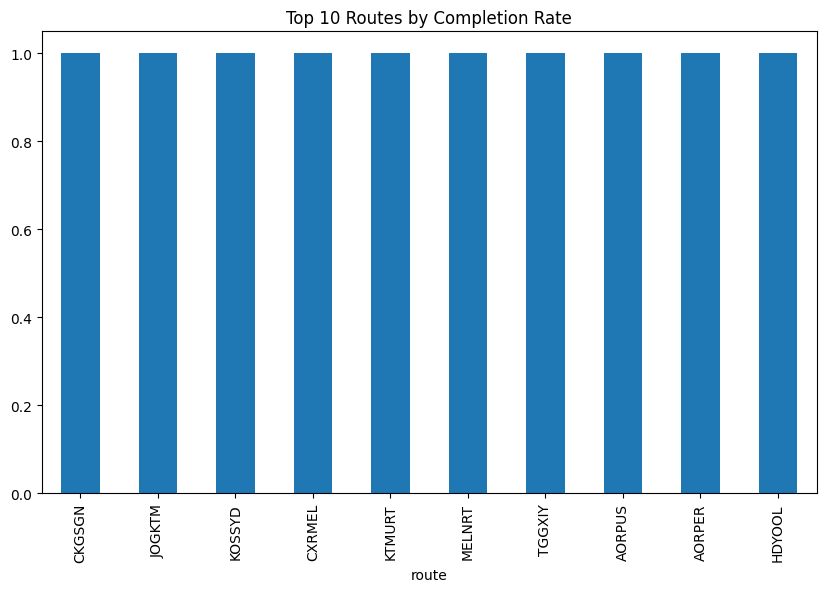

In [21]:
route_completion = df.groupby('route')['booking_complete'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))
route_completion.head(10).plot(kind='bar')
plt.title("Top 10 Routes by Completion Rate")
plt.show()


In [22]:
# ---- TARGET ENCODING WITH SMOOTHING ----
def target_encode(df, col, target, smoothing=10):
    
    global_mean = df[target].mean()
    
    stats = df.groupby(col)[target].agg(['mean', 'count'])
    
    smooth = (stats['mean'] * stats['count'] + global_mean * smoothing) / \
             (stats['count'] + smoothing)
    
    df[col] = df[col].map(smooth)
    
    return df

df = target_encode(df, 'route', 'booking_complete', smoothing=20)
df = target_encode(df, 'booking_origin', 'booking_complete', smoothing=10)

In [23]:
df = pd.get_dummies(
    df,
    columns=['trip_type', 'sales_channel'],
    drop_first=True,
    dtype=int
)

In [24]:
#Skewed Variable Transformation
df['purchase_lead'] = np.log1p(df['purchase_lead'])
df['length_of_stay'] = np.log1p(df['length_of_stay'])

In [25]:
df.head()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete,trip_type_OneWay,trip_type_RoundTrip,sales_channel_Mobile
0,2,5.572154,2.995732,7,6,0.07478,0.051195,1,0,0,5.52,0,0,1,0
1,1,4.727388,3.044522,3,6,0.07478,0.051195,0,0,0,5.52,0,0,1,0
2,2,5.497168,3.135494,17,3,0.07478,0.103512,1,1,0,5.52,0,0,1,0
3,1,4.574711,3.465736,4,6,0.07478,0.051195,0,0,1,5.52,0,0,1,0
4,2,4.234107,3.135494,15,3,0.07478,0.103512,1,0,1,5.52,0,0,1,0


In [26]:
X= df.drop('booking_complete',axis=1)
y= df.booking_complete         

#changing object dtype to int dtype
for colname in X.select_dtypes("object"):
    X[colname], _ = X[colname].factorize()

from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(X, y)
mi_scores = pd.Series(mi_scores, name="MI Scores", index=X.columns)
mi_scores = mi_scores.sort_values(ascending=False)

mi_scores # show a few features with their MI scores

route                    0.054401
booking_origin           0.047434
flight_duration          0.014095
wants_extra_baggage      0.011711
trip_type_RoundTrip      0.008847
length_of_stay           0.006536
purchase_lead            0.004240
flight_day               0.003273
num_passengers           0.003134
wants_in_flight_meals    0.002959
wants_preferred_seat     0.002636
trip_type_OneWay         0.000823
flight_hour              0.000000
sales_channel_Mobile     0.000000
Name: MI Scores, dtype: float64

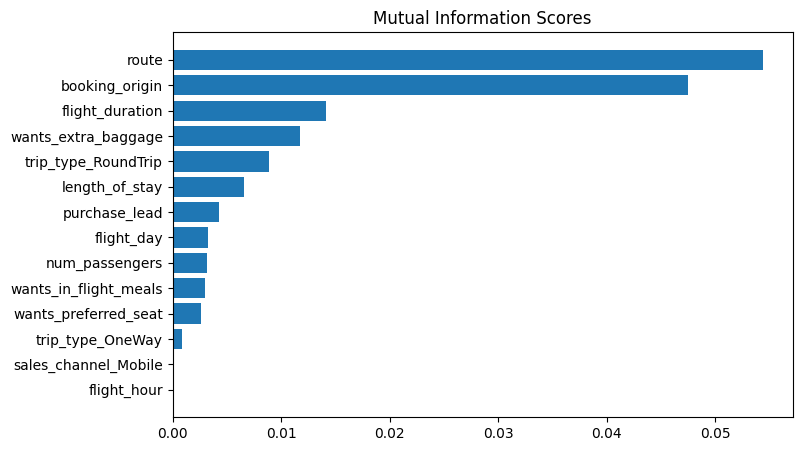

In [44]:
def plot_mi_scores(scores):
    scores = scores.sort_values(ascending=True)
    width = np.arange(len(scores))
    ticks = list(scores.index)
    plt.barh(width, scores)
    plt.yticks(width, ticks)
    plt.title("Mutual Information Scores")


plt.figure(dpi=100, figsize=(8, 5))
plot_mi_scores(mi_scores)


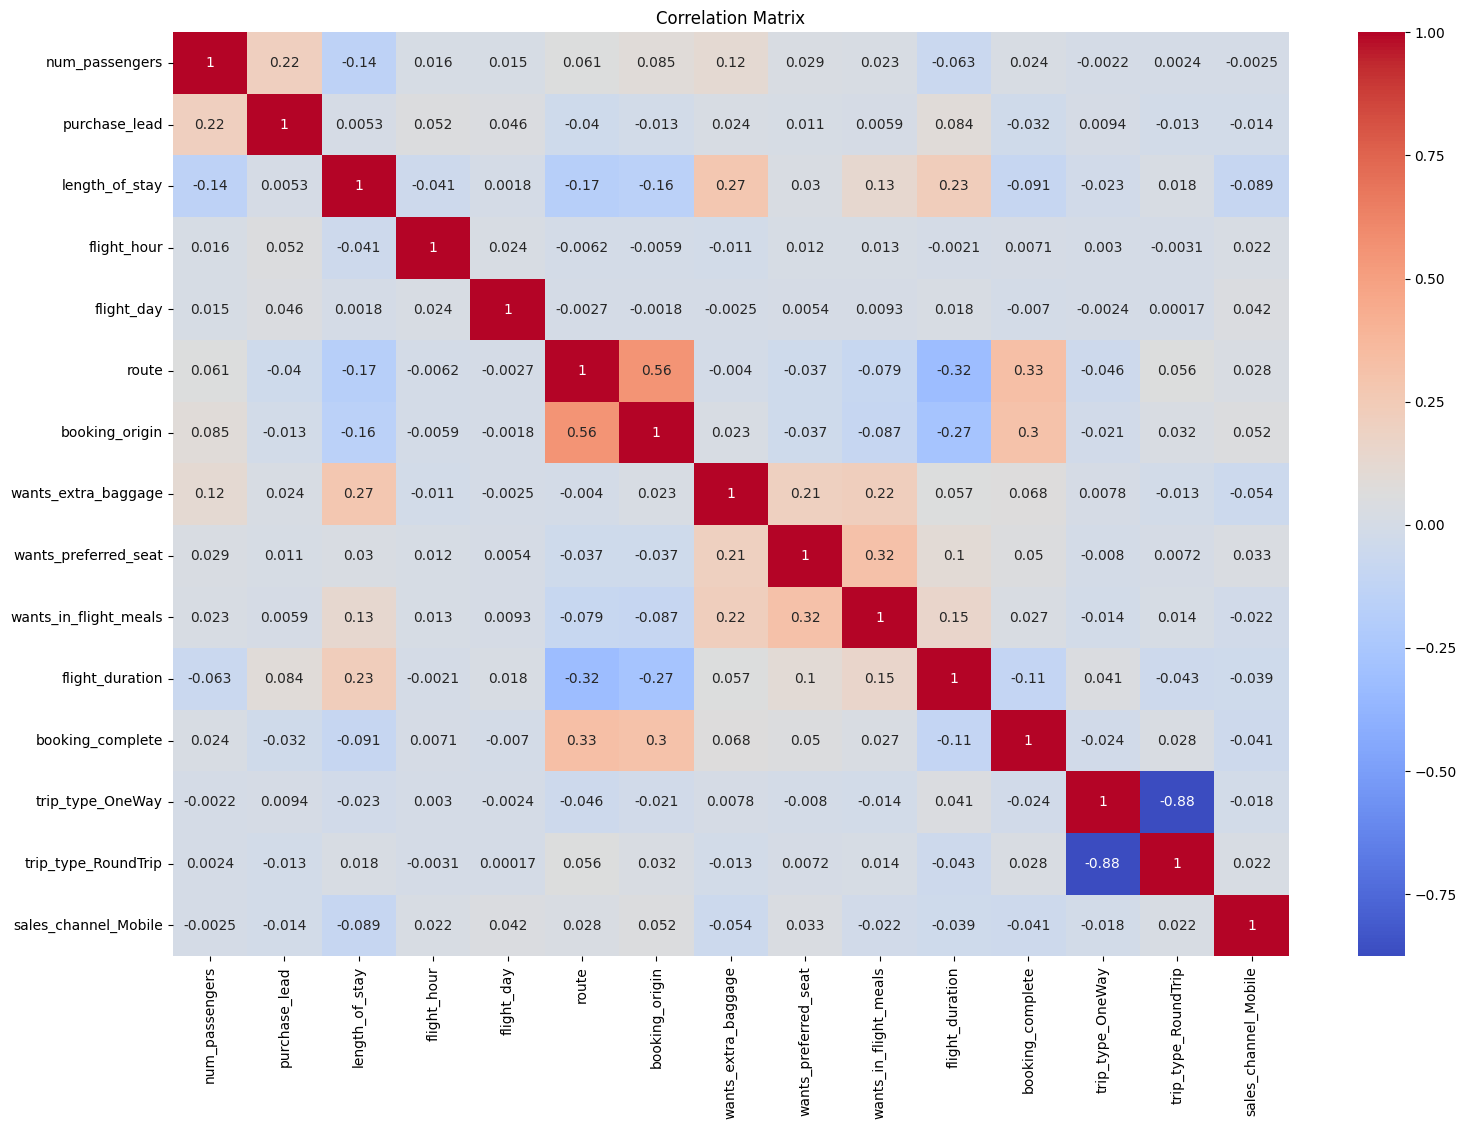

In [27]:
plt.figure(figsize=(18,12))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()


In [28]:
df.columns

Index(['num_passengers', 'purchase_lead', 'length_of_stay', 'flight_hour',
       'flight_day', 'route', 'booking_origin', 'wants_extra_baggage',
       'wants_preferred_seat', 'wants_in_flight_meals', 'flight_duration',
       'booking_complete', 'trip_type_OneWay', 'trip_type_RoundTrip',
       'sales_channel_Mobile'],
      dtype='object')

In [29]:
selected_features=['num_passengers','purchase_lead', 'length_of_stay','route', 'booking_origin', 'wants_extra_baggage',
       'wants_preferred_seat','flight_duration','trip_type_OneWay', 'trip_type_RoundTrip',
       'sales_channel_Mobile']

X = df[selected_features]
y = df['booking_complete']

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [43]:
#logistic regression
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000,class_weight='balanced'))
])

pipeline.fit(X_train, y_train)
y_pred_lr=pipeline.predict(X_test)
y_prob_lr = pipeline.predict_proba(X_test)[:,1]

print("LogReg AUC:", roc_auc_score(y_test, y_prob_lr))
print(classification_report(y_test, y_pred_lr))

LogReg AUC: 0.7906347390469913
              precision    recall  f1-score   support

           0       0.94      0.73      0.82      8504
           1       0.32      0.73      0.45      1496

    accuracy                           0.73     10000
   macro avg       0.63      0.73      0.63     10000
weighted avg       0.85      0.73      0.76     10000



In [42]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, classification_report

scale_pos_weight = 8504 / 1496

model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    scale_pos_weight=scale_pos_weight
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

print("AUC:", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred))

AUC: 0.8071151873795785
              precision    recall  f1-score   support

           0       0.95      0.70      0.81      8504
           1       0.31      0.77      0.44      1496

    accuracy                           0.71     10000
   macro avg       0.63      0.74      0.63     10000
weighted avg       0.85      0.71      0.75     10000



In [41]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    random_state=42,
    class_weight='balanced'
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:,1]

print("RF AUC:", roc_auc_score(y_test, y_prob_rf))
print(classification_report(y_test, y_pred_rf))

RF AUC: 0.805221221784275
              precision    recall  f1-score   support

           0       0.95      0.70      0.81      8504
           1       0.31      0.77      0.45      1496

    accuracy                           0.71     10000
   macro avg       0.63      0.74      0.63     10000
weighted avg       0.85      0.71      0.75     10000

